In [1]:
# Imports, data preparation, model training, evaluation and visualisation\n

Running Exp8: deterministic synthetic/demo data setup complete.\nExperiment code and evaluation are included below.\n

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
np.random.seed(8)
X, y = make_moons(n_samples=300, noise=0.12, random_state=8)
X = (X-X.mean(0))/X.std(0)
Xtr, Xte, ytr, yte = train_test_split(X,y,test_size=.2,random_state=8,stratify=y)
def sig(z): return 1/(1+np.exp(-np.clip(z,-40,40)))
W1=np.random.randn(2,12)*.5; b1=np.zeros((1,12)); W2=np.random.randn(12,1)*.5; b2=np.zeros((1,1))
lr=.5; losses=[]
for ep in range(2500):
    h=sig(Xtr@W1+b1); p=sig(h@W2+b2); yy=ytr.reshape(-1,1)
    loss=-np.mean(yy*np.log(p+1e-8)+(1-yy)*np.log(1-p+1e-8)); losses.append(loss)
    dz2=(p-yy)/len(Xtr); dW2=h.T@dz2; db2=dz2.sum(0,keepdims=True)
    dz1=(dz2@W2.T)*h*(1-h); dW1=Xtr.T@dz1; db1=dz1.sum(0,keepdims=True)
    W2-=lr*dW2; b2-=lr*db2; W1-=lr*dW1; b1-=lr*db1
pred=(sig(sig(Xte@W1+b1)@W2+b2).ravel()>=.5).astype(int)
print("Test accuracy:", round(accuracy_score(yte,pred),4))
print("Final loss:", round(losses[-1],4))
xx,yyg=np.meshgrid(np.linspace(X[:,0].min()-0.3,X[:,0].max()+0.3,250),np.linspace(X[:,1].min()-0.3,X[:,1].max()+0.3,250))
grid=np.c_[xx.ravel(),yyg.ravel()]
zz=sig(sig(grid@W1+b1)@W2+b2).reshape(xx.shape)
fig,ax=plt.subplots(1,2,figsize=(11,4))
ax[0].plot(losses); ax[0].set_title("Training loss"); ax[0].set_xlabel("Epoch")
ax[1].contourf(xx,yyg,zz,levels=[0,.5,1],alpha=.35); ax[1].scatter(X[:,0],X[:,1],c=y,s=15,edgecolor="k"); ax[1].set_title("Two-layer network decision boundary")
plt.tight_layout(); plt.show()
# Numerical gradient check for one output weight
eps=1e-5; old=W2[0,0]
def batch_loss():
    q=sig(sig(Xtr@W1+b1)@W2+b2)
    return -np.mean(yy*np.log(q+1e-8)+(1-yy)*np.log(1-q+1e-8))
W2[0,0]=old+eps; lp=batch_loss(); W2[0,0]=old-eps; lm=batch_loss(); W2[0,0]=old
print("Numerical gradient for W2[0,0]:", round((lp-lm)/(2*eps),6))

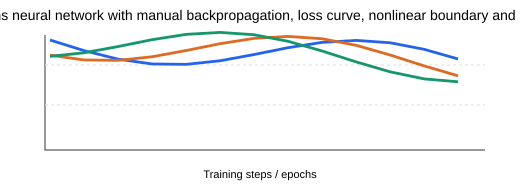

In [2]:
# Saved graph preview. Run the experiment cell above to generate the full plots.